In [218]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
import ot
from openTSNE import TSNE
from openTSNE.affinity import Affinities
from scipy.sparse import block_array
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

In [219]:
plt.style.use('notebooks/style.mplstyle')

## Functions

In [261]:
def get_ring(n, r=1, seed=0):
    np.random.seed(seed)
    theta = np.sort(2 * np.pi * np.random.rand(n))

    r = 1 + 0.2 * np.random.rand(n)
    r *=r

    x = np.cos(theta)
    y = np.sin(theta)

    x *= r
    y *= r
    return np.stack([x,y], axis=1)

def get_blob(n, sig=1, seed=0):
    np.random.seed(seed)

    return np.random.randn(n, 2)*sig

def get_disc(n, r=1, seed=0):
    np.random.seed(seed)
    theta = 2 * np.pi * np.random.rand(n)
    # sqrt of a uniform makes the density uniform over the area rather than over the radius
    rad = r * np.sqrt(np.random.rand(n))

    return np.stack([rad * np.cos(theta), rad * np.sin(theta)], axis=1)

def get_wiggly_line(n, length=2.0, amp=0.25, n_waves=1.5, jitter=0.05, seed=0):
    np.random.seed(seed)
    x = np.sort(np.random.rand(n)) * length
    y = amp * np.sin(2 * np.pi * n_waves * x / length) + jitter * np.random.randn(n)

    return np.stack([x, y], axis=1)

In [221]:
def get_edges(nbrs, keys, queries, k, drop_self=True):
    # column 0 is the query point itself only when keys and queries are the same set.
    # for cross-batch queries it is the genuine nearest neighbour, so keep it.
    _, indices = nbrs.kneighbors(queries)
    indices = indices[:, 1:k+1] if drop_self else indices[:, :k]
    edges = np.stack([np.repeat(np.arange(len(queries)), k), indices.flatten()], axis=-1)
    segments = np.stack([queries[edges[:, 0]], keys[edges[:, 1]]], axis=1)
    return edges, segments


def first_per_point(arr, k, m):
    """Keep the m nearest of each query point's k edges.

    Relies on get_edges emitting each query's k edges contiguously and distance-sorted,
    so no re-sorting or distance recomputation is needed. Works both for the (n*k, 2)
    edge arrays and the (n*k, 2, d) segment arrays.
    """
    return arr.reshape(len(arr) // k, k, *arr.shape[1:])[:, :m].reshape(-1, *arr.shape[1:])


In [222]:

def sparsify_plan(P, mode=None, k=15):
    if mode is None:
        P_sparse = P

    elif mode == "topk":
        P_sparse = np.zeros_like(P)
        for i in range(P.shape[0]):
            idx = np.argpartition(P[i], -k)[-k:]
            P_sparse[i, idx] = 1
        for j in range(P.shape[1]):
            idx = np.argpartition(P[:, j], -k)[-k:]
            P_sparse[idx, j] = 1

    elif mode == "weighted_topk":
        P_sparse = np.zeros_like(P)
        for i in range(P.shape[0]):
            idx = np.argpartition(P[i], -k)[-k:]
            P_sparse[i, idx] = P[i, idx]
        for j in range(P.shape[1]):
            idx = np.argpartition(P[:, j], -k)[-k:]
            P_sparse[idx, j] = P[idx, j]
    else:

        raise NotImplementedError

    return P_sparse

In [223]:
def subsample(x, num, seed=0):
    np.random.seed(seed)
    r = np.random.randn(len(x))
    part = np.argsort(r)
    if isinstance(num, int):
        n = num
    else:
        n = np.floor(len(x)*num).astype(int)
    return x[part[:n]]


In [224]:
def run_case(batch1, batch2, k=12, m_plot=3, seed=0, ot_eps_div=200, ot_maxiter=3000):
    """Build the four affinity graphs for one pair of batches and embed each of them.

    Returns the segments needed for the input row and the four embeddings for the output row.
    """

    # get knn and mutual knn edges
    nbrs1 = NearestNeighbors(n_neighbors=k+1, algorithm='auto').fit(batch1)
    edges11, segments11 = get_edges(nbrs1, batch1, batch1, k)
    edges12, segments12 = get_edges(nbrs1, batch1, batch2, k, drop_self=False)

    nbrs2 = NearestNeighbors(n_neighbors=k+1, algorithm='auto').fit(batch2)
    edges21, segments21 = get_edges(nbrs2, batch2, batch1, k, drop_self=False)
    edges22, segments22 = get_edges(nbrs2, batch2, batch2, k)


    # within batch kNN
    sep_graph = sp.coo_matrix((np.ones(len(edges11)+ len(edges22)),
                               (np.concatenate([edges11[:, 0], edges22[:, 0]+len(batch1)]),
                                np.concatenate([edges11[:, 1], edges22[:, 1]+len(batch1)]))),
                                shape=(len(batch1)+ len(batch2), len(batch1)+ len(batch2)))
    sep_graph = sep_graph.maximum(sep_graph.T)


    # cross batch
    graph12 = sp.coo_matrix(( np.ones(len(edges12)), (edges12[:,0], edges12[:, 1])), shape=(len(batch2), len(batch1)))
    graph21 = sp.coo_matrix(( np.ones(len(edges21)), (edges21[:,1], edges21[:, 0])), shape=(len(batch2), len(batch1)))

    # mutual kNN
    m_graph = graph12.minimum(graph21).tocoo()

    sep_m_graph = sep_graph +  block_array([[None, m_graph],
                                            [m_graph.T,  None],],
                                           format="csr")
    sep_m_graph /= sep_m_graph.sum()


    m_edges = np.stack([m_graph.row, m_graph.col], axis=-1)
    m_segments = np.stack([batch2[m_edges[:, 0]], batch1[m_edges[:, 1]]], axis=1)

    # shared kNN
    s_graph = graph12.maximum(graph21).tocoo()
    sep_s_graph = sep_graph +  block_array([[None, s_graph],
                                            [s_graph.T,  None],],
                                           format="csr")
    sep_s_graph /= sep_s_graph.sum()

    s_edges = np.stack([s_graph.row, s_graph.col], axis=-1)
    s_segments = np.stack([batch2[s_edges[:, 0]], batch1[s_edges[:, 1]]], axis=1)


    # shared kNN restricted to each point's m_plot nearest cross-batch neighbours, for drawing
    # only. the full-k graphs above still drive the embeddings. going through the sparse union
    # deduplicates edges that both directions find, which would otherwise be drawn twice.
    e12_top = first_per_point(edges12, k, m_plot)
    e21_top = first_per_point(edges21, k, m_plot)

    g12_top = sp.coo_matrix((np.ones(len(e12_top)), (e12_top[:, 0], e12_top[:, 1])),
                            shape=(len(batch2), len(batch1)))
    g21_top = sp.coo_matrix((np.ones(len(e21_top)), (e21_top[:, 1], e21_top[:, 0])),
                            shape=(len(batch2), len(batch1)))

    s_graph_plot = g12_top.maximum(g21_top).tocoo()
    s_edges_plot = np.stack([s_graph_plot.row, s_graph_plot.col], axis=-1)
    s_segments_plot = np.stack([batch2[s_edges_plot[:, 0]], batch1[s_edges_plot[:, 1]]], axis=1)


    # get ot plan
    dist = ot.dist(batch1, batch2)

    eps = np.median(dist) / ot_eps_div

    P = ot.sinkhorn(np.ones(len(batch1))/len(batch1),
                    np.ones(len(batch2))/len(batch2),
                            dist,
                            reg=eps,
                            numItermax=ot_maxiter,
                            stopThr=1e-12)

    P_sp = sp.coo_matrix(sparsify_plan(P, mode="topk", k=k))

    ot_segments = np.stack([batch1[P_sp.row], batch2[P_sp.col]], axis=1)


    # highest-mass couplings per point, for drawing only. topk keeps the top k per row and per
    # column, so every point ends up with at least k_sub partners and none is left isolated.
    k_sub = m_plot
    P_sp_sub = sp.coo_matrix(sparsify_plan(P, mode="topk", k=k_sub))

    ot_segments_sub = np.stack([batch1[P_sp_sub.row], batch2[P_sp_sub.col]], axis=1)

    sep_ot_graph = sep_graph +  block_array([[None, P_sp],
                                            [P_sp.T,  None],],
                                           format="csr")
    sep_ot_graph /= sep_ot_graph.sum()

    # only normalize sep_graph here so not have it dwarfed by the off-diag blocks
    sep_graph /= sep_graph.sum()


    # get embeddings, all from the same initialization so only the affinities differ
    init = np.concatenate([batch1, batch2])[:, :2] / 10000

    embds = {}
    for name, graph in [("joint_tsne", sep_graph), ("m_tsne", sep_m_graph),
                        ("s_tsne", sep_s_graph), ("ot_tsne", sep_ot_graph)]:
        aff = Affinities()
        aff.P = graph
        embedder = TSNE(
            n_components=2,
            random_state=seed,
            verbose=False,
        )
        embds[name] = embedder.fit(affinities=aff, initialization=init)

    return {"segments11": segments11, "segments22": segments22,
            "segments12": segments12, "segments21": segments21,
            "m_segments": m_segments,
            "s_segments": s_segments, "s_segments_plot": s_segments_plot,
            "ot_segments": ot_segments, "ot_segments_sub": ot_segments_sub,
            "sep_graph": sep_graph, "sep_m_graph": sep_m_graph,
            "sep_s_graph": sep_s_graph, "sep_ot_graph": sep_ot_graph,
            **embds}

In [225]:
def plot_case(batch1, batch2, res, n0, savepath=None, letters="abcdefghij",
              s=5, alpha=0.2, m_frac=0.5, sub_seed=0, plot_seed=0, dpi=300):
    """Input row (data + edges) over output row (embeddings), one column per method.

    n0 is the size of the first component of each batch, which is drawn with circles while
    the second one gets crosses.
    """
    fig, ax = plt.subplots(ncols=4, nrows=2, figsize=(5.5, 2.0), dpi=200, constrained_layout=True,
                           gridspec_kw={"wspace": 0.2,"wspace": 0.0},)

    col_titles = ["naive kNN", "a + cross mutual kNN", "a + cross shared kNN", "a + optimal transport"]
    row_titles = ["Input", "Output"]

    n1, n2 = len(batch1), len(batch2)

    colors = np.array(
        ["C0"] * n0
        + ["C0"] * (n1 - n0)
        + ["C1"] * n0
        + ["C1"] * (n2 - n0)
    )

    # first component of either batch gets circles, second one crosses
    is_first = np.concatenate([np.arange(n1) < n0, np.arange(n2) < n0])
    order = np.random.default_rng(plot_seed).permutation(n1 + n2)
    order_1 = order[is_first[order]]
    order_2 = order[~is_first[order]]

    for cax, letter, ctitle in zip(ax[0], letters[:len(ax[0])], col_titles):
        cax.text(x=0.5,
                 y=1.0,
                 s=ctitle,
                 transform=cax.transAxes,
                 ha="center",
                 va="bottom",)


        cax.text(
        -0.04,
        1.0,
        f"{letter}",
        transform=cax.transAxes,
        ha="left",
        va="bottom",
        fontweight="bold",
        fontsize=7
        )

    for cax, rtitle in zip(ax[:, 0], row_titles):
        cax.text(x=-0.1, y=0.5, s=rtitle, rotation=90, transform=cax.transAxes)


    for cax in ax[0]:
        cax.scatter(*batch1[:n0, :2].T, c="C0", edgecolors="none",  s=s)
        cax.scatter(*batch1[n0:, :2].T, c="C0", edgecolors="none",  marker="X", s=s)

        cax.scatter(*batch2[:n0, :2].T, c="C1", edgecolors="none",  s=s)
        cax.scatter(*batch2[n0:, :2].T, c="C1", edgecolors="none",  marker="X", s=s)


    ax[0, 0].add_collection(LineCollection(res["segments11"][:, :, :2], linewidths=0.5, alpha=alpha, color="k", zorder=-1))
    ax[0, 0].add_collection(LineCollection(res["segments22"][:, :, :2], linewidths=0.5, alpha=alpha, color="k", zorder=-1))

    # mutual kNN keeps the random edge subsample: most points have no mutual edge at all, so a
    # per-point rule is not defined here
    ax[0, 1].add_collection(LineCollection(subsample(res["m_segments"][:, :, :2], num=m_frac, seed=sub_seed), linewidths=0.5, alpha=alpha, linestyle="solid", color="k", zorder=-1))

    ax[0, 2].add_collection(LineCollection(res["s_segments_plot"][:, :, :2], linewidths=0.5, alpha=alpha, linestyle="solid", color="k", zorder=-1))

    ax[0, 3].add_collection(LineCollection(res["ot_segments_sub"][:, :, :2], linewidths=0.5, alpha=alpha, linestyle="solid", color="k", zorder=-1))


    for cax, key in zip(ax[1], ["joint_tsne", "m_tsne", "s_tsne", "ot_tsne"]):
        cax.scatter(*res[key][order_1].T, c=colors[order_1], edgecolors="none",  s=s)
        cax.scatter(*res[key][order_2].T, c=colors[order_2], marker="X", edgecolors="none",  s=s)


    for i, cax in enumerate(ax.T.flatten()):
        cax.axis("off")
        cax.set_aspect("equal", "datalim")


    handles_batch = [
        Patch(facecolor="C0", label="Batch 1"),
        Patch(facecolor="C1", label="Batch 2"),

    ]

    ax[0,3].legend(handles=handles_batch, loc=(1.0, 0.3), frameon=False,  fontsize=7, ncols=1)


    fig.canvas.draw()

    for j in range(3):
        right = ax[0, j].get_position().x1
        left  = ax[0, j + 1].get_position().x0
        x = (right + left) / 2

        fig.add_artist(Line2D(
            [x, x], [0.08, 0.95],
            transform=fig.transFigure,
            color="0.8",
            linewidth=0.8,
        ))

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi)

    return fig

## Case 1: ring and blob

In [314]:
# case 1: a ring plus a Gaussian blob

seed = 5 # 2, 5 good

n = 40 # 40 50
f = 1 # relative size of other batch

k = 12      # neighbours per point, within and across batches
m_plot = 3  # cross-batch edges drawn per point in the top row

shift = np.array([0, -3.5])

# add some high-dim noise for more stable embds
noise_sig = 0.1
noise_dims = 38

ring1 = get_ring(n, seed=seed)
blob1 = get_blob(n, sig=0.5, seed=seed)
batch1 = np.concatenate([ring1, blob1+np.array([4,0])], axis=0)

ring2 = get_ring(n*f, seed=seed+1)
blob2 = get_blob(n*f, sig=0.5, seed=seed+1)
batch2 = np.concatenate([ring2, blob2+np.array([4,0])], axis=0)

batch2 += shift

batch1 = np.concatenate([batch1, np.random.randn(len(batch1), noise_dims) * noise_sig], axis=1)
batch2 = np.concatenate([batch2, np.random.randn(len(batch2), noise_dims) * noise_sig], axis=1)

In [315]:
res = run_case(batch1, batch2, k=k, m_plot=m_plot, seed=seed)

/gpfs01/berens/user/sdamrich/mirrored_code/ne_aligned/.venv/lib/python3.12/site-packages/ot/bregman/_sinkhorn.py:667: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


In [316]:
# mean degree of each affinity graph
{name: res[name].nnz / len(batch1) for name in ["sep_graph", "sep_m_graph", "sep_s_graph", "sep_ot_graph"]}

{'sep_graph': 28.8,
 'sep_m_graph': 36.65,
 'sep_s_graph': 68.95,
 'sep_ot_graph': 56.075}

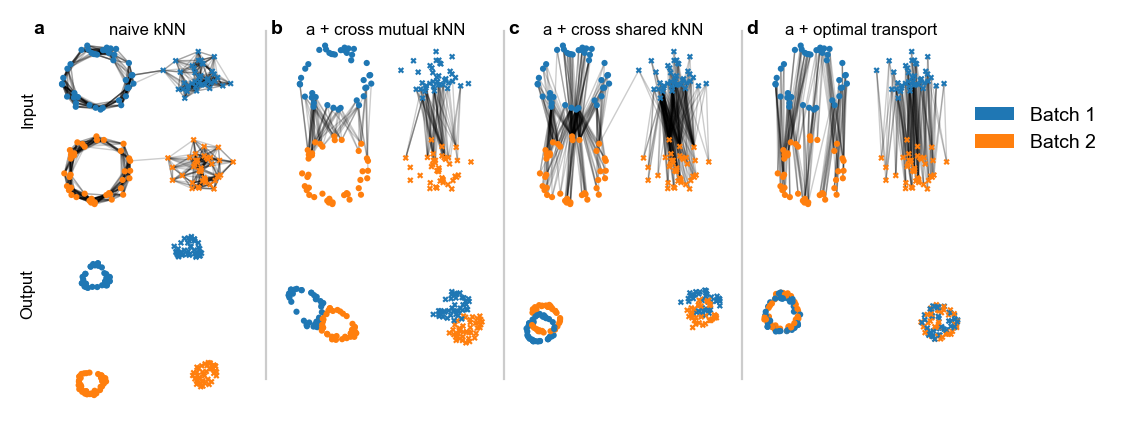

In [317]:
fig=plot_case(batch1, batch2, res, n0=n, sub_seed=seed+2, savepath="fig1.png")
fig.savefig("cross_edge_circle.png", dpi=300)

## Case 2: disc and wiggly line

In [310]:
# case 2: a uniform disc plus a slightly wiggly, mostly horizontal line

seed_dl = 4 # 2, 4 good

n_dl = 30
f_dl = 1

k_dl = 8
m_plot_dl = 3

disc_r = 0.8 # keeps the batch gap relative to the shape size close to case 1
line_offset = np.array([2., 0])
shift_dl = np.array([0, -2.5])

noise_sig_dl = 0.1
noise_dims_dl = 38

disc1 = get_disc(n_dl, r=disc_r, seed=seed_dl)
line1 = get_wiggly_line(n_dl, seed=seed_dl)
batch1_dl = np.concatenate([disc1, line1 + line_offset], axis=0)

disc2 = get_disc(n_dl*f_dl, r=disc_r, seed=seed_dl+1)
line2 = get_wiggly_line(n_dl*f_dl, seed=seed_dl+1)
batch2_dl = np.concatenate([disc2, line2 + line_offset], axis=0)

batch2_dl += shift_dl

# seeded explicitly so the noise does not depend on whether case 1 was run before
np.random.seed(seed_dl+10)

batch1_dl = np.concatenate([batch1_dl, np.random.randn(len(batch1_dl), noise_dims_dl) * noise_sig_dl], axis=1)
batch2_dl = np.concatenate([batch2_dl, np.random.randn(len(batch2_dl), noise_dims_dl) * noise_sig_dl], axis=1)

In [311]:
res_dl = run_case(batch1_dl, batch2_dl, k=k_dl, m_plot=m_plot_dl, seed=seed_dl)

/gpfs01/berens/user/sdamrich/mirrored_code/ne_aligned/.venv/lib/python3.12/site-packages/ot/bregman/_sinkhorn.py:667: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


In [312]:
# mean degree of each affinity graph
{name: res_dl[name].nnz / len(batch1_dl) for name in ["sep_graph", "sep_m_graph", "sep_s_graph", "sep_ot_graph"]}

{'sep_graph': 20.333333333333332,
 'sep_m_graph': 25.233333333333334,
 'sep_s_graph': 47.43333333333333,
 'sep_ot_graph': 38.86666666666667}

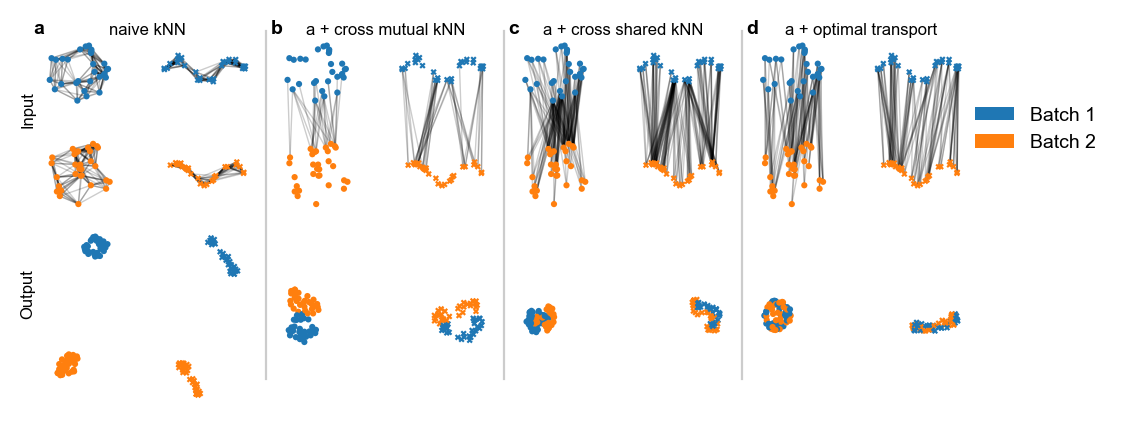

In [313]:
fig = plot_case(batch1_dl, batch2_dl, res_dl, n0=n_dl, sub_seed=seed_dl+2, savepath="fig1_disc_line.png")
fig.savefig("cross_edge_line.png", dpi=300)